# 3 · Does a more detailed model earn its complexity?

The earlier notebooks established the basketball candidates and their pregame timing. Now I want to see what they buy: **can a model do more than favor the stronger season record, and are nonlinear models worth the extra flexibility?**

I separate two tasks. A winner rule picks a side; a probability model also expresses how uncertain that pick is. Accuracy is useful for the first question. Log loss and Brier score reward useful probabilities, so model selection prioritizes log loss rather than a threshold chosen for a good-looking accuracy.

This notebook reconstructs the actual development process: chronological windows, the 74 candidate configurations, model-family comparisons, common-input comparisons, regularization, feature choices and the final selection rule. The original 2023–24 test is excluded. A new better-record reporting baseline is added retrospectively without changing the selected model.

In [1]:
from pathlib import Path
import sys, json

ROOT = Path.cwd() if (Path.cwd() / "Data").exists() else Path.cwd().parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from src.charts import feature_label

TABLES = ROOT / "artifacts/tables"
FIGURES = ROOT / "artifacts/figures"
CLAY, TEAL = "#b55832", "#427b83"
plt.rcParams.update(
    {
        "axes.spines.top": False,
        "axes.spines.right": False,
        "figure.figsize": (9, 4),
        "axes.grid": False,
        "font.size": 10,
    }
)
pd.set_option("display.max_columns", 14)


def finish(fig, filename=None):
    fig.tight_layout()
    if filename:
        fig.savefig(FIGURES / filename, dpi=160, bbox_inches="tight")
    plt.show()

In [2]:
from src.analysis import better_record_picks, model_family
from src.modeling import make_model, metrics, select_candidate
from src.features import feature_sets

data = pd.read_csv(TABLES / "matchups.csv.gz", parse_dates=["gamedate"])
dev = data[data.eligible & data.season.lt(2023)].copy()
summary = pd.read_csv(TABLES / "cv_summary.csv")
folds = pd.read_csv(TABLES / "cv_folds.csv")
configs = json.loads((TABLES / "candidate_configs.json").read_text())
selection = json.loads((ROOT / "artifacts/models/selection.json").read_text())
sets = feature_sets()
by_name = {c["name"]: c for c in configs}
print("Development games:", len(dev), "Candidate configurations:", len(configs))

Development games: 9344 Candidate configurations: 74


## 1. Make the forecast chronology explicit

Randomly splitting game rows would place future seasons in training and mix overlapping team histories across evaluation groups. Instead, I begin with three complete training seasons and repeatedly add a season to the training window. Every validation season is later than every game used to fit that fold.

Features update as completed games become available within the validation season; the fitted parameters do not. This represents a sequence of pregame predictions, not a forecast of an entire season made in October.

,evaluation_season,stage,first_train_season,last_train_season,train_games,evaluation_games,last_train_date,first_evaluation_date
0,2017,Validation,2014,2016,3219,1075,2017-04-12,2017-11-06
1,2018,Validation,2014,2017,4294,1074,2018-04-11,2018-11-05
2,2019,Validation,2014,2018,5368,906,2019-04-10,2019-11-12
3,2020,Validation,2014,2019,6274,924,2020-08-14,2021-01-10
4,2021,Validation,2014,2020,7198,1073,2021-05-16,2021-11-08
5,2022,Validation,2014,2021,8271,1073,2022-04-10,2022-11-07
6,2023,Final test,2014,2022,9344,1074,2023-04-09,2023-11-14


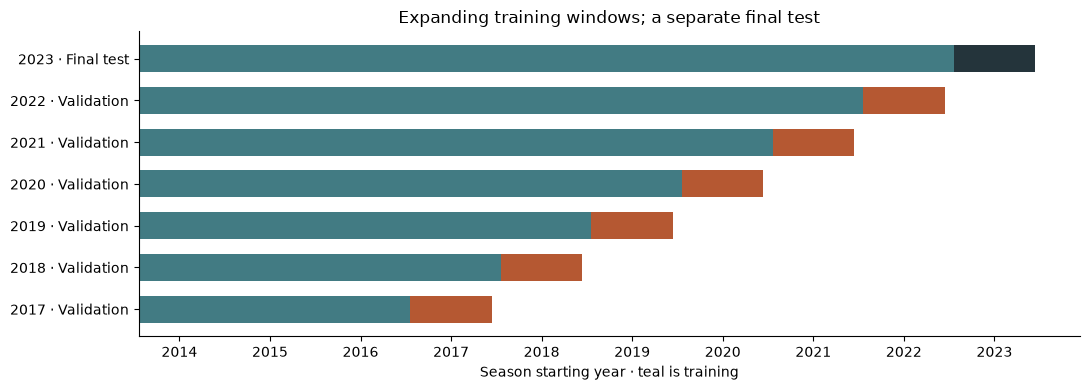

In [3]:
timeline = pd.read_csv(TABLES / "split_timeline.csv")
display(timeline)
years = np.arange(2014, 2024)
fig, ax = plt.subplots(figsize=(11, 4))
for i, row in timeline.iterrows():
    ax.barh(
        i,
        row.last_train_season - row.first_train_season + 1,
        left=row.first_train_season - 0.45,
        height=0.65,
        color=TEAL,
    )
    ax.barh(
        i,
        0.9,
        left=row.evaluation_season - 0.45,
        height=0.65,
        color=CLAY if row.stage == "Validation" else "#24343b",
    )
ax.set_yticks(
    range(len(timeline)),
    [f"{r.evaluation_season} · {r.stage}" for r in timeline.itertuples()],
)
ax.set_xticks(years)
ax.set(
    xlabel="Season starting year · teal is training",
    title="Expanding training windows; a separate final test",
)
finish(fig, "story_validation_design.png")
for season in range(2017, 2023):
    assert (
        dev.loc[dev.season.lt(season), "gamedate"].max()
        < dev.loc[dev.season.eq(season), "gamedate"].min()
    )

The six validation seasons contain different numbers of games, including shortened seasons. I average the six season scores equally for selection. A pooled score would weight longer seasons more; neither weighting is universally correct, but the choice should be explicit. The final fit can use all 9,344 development games after the choice is fixed.

## 2. Start with “pick the better record”

The decision rule uses only season-to-date winning percentage before the game. Exact percentage ties favor the home team. It has no fitted parameter. Cross-multiplying integer wins and games handles ties such as 2/6 and 3/9 correctly after CSV rounding.

This is deliberately different from the pre-existing win-percentage logistic baseline: that model learns how record differences and home advantage translate into a probability. We should keep both comparisons, not rename one as the other.

In [4]:
picks = better_record_picks(dev)
example = (
    dev[
        [
            "gamedate",
            "home_off_team",
            "away_off_team",
            "home_prior_games",
            "away_prior_games",
            "home_win_pct",
            "away_win_pct",
        ]
    ]
    .join(picks)
    .head(8)
)
display(example)
record_by_season = pd.read_csv(TABLES / "decision_by_season.csv")
validation_record = record_by_season.query("stage == 'Validation'")
display(
    validation_record[
        ["season", "games", "ties", "record_accuracy", "model_accuracy"]
    ].round(4)
)
print(
    "Mean validation-season record-rule accuracy:",
    validation_record.record_accuracy.mean(),
)

,gamedate,home_off_team,away_off_team,home_prior_games,away_prior_games,home_win_pct,away_win_pct,home_prior_wins,away_prior_wins,record_tie,record_pick_home
145,2014-11-17,CHA,DAL,10,10,0.400000,0.700000,4,7,False,0
149,2014-11-17,DET,ORL,10,11,0.300000,0.363636,3,4,False,0
150,2014-11-17,MEM,HOU,10,10,0.900000,0.900000,9,9,True,1
155,2014-11-18,MIL,NYK,10,11,0.500000,0.272727,5,3,False,1
156,2014-11-18,UTA,OKC,11,11,0.363636,0.272727,4,3,False,1
159,2014-11-19,IND,CHA,11,11,0.363636,0.363636,4,4,True,1
163,2014-11-19,BKN,MIL,10,11,0.400000,0.545455,4,6,False,0
164,2014-11-19,DET,PHX,11,11,0.272727,0.545455,3,6,False,0


,season,games,ties,record_accuracy,model_accuracy
3,2017,1075,22,0.6558,0.6800
4,2018,1074,12,0.6350,0.6732
5,2019,906,13,0.6457,0.6468
6,2020,924,15,0.6418,0.6439
7,2021,1073,16,0.6198,0.6440
8,2022,1073,26,0.5983,0.6226


Mean validation-season record-rule accuracy: 0.6327289449333333


A hard winner choice supplies no calibrated probability. Assigning it 100% confidence would manufacture a poor log loss rather than provide a fair comparison. I therefore compare winner accuracy directly, and retain fitted record/net-rating baselines for probability quality. These development scores are part of the explanation, not a second independent test.

## 3. Fit simple probability baselines in one actual validation window

For a concrete example, I reproduce the 2022–23 validation fold: train on 2014–15 through 2021–22, then predict the next full season. The historical home-win rate is estimated from that training set. One-variable logistic models add either record difference or net-rating difference, with an intercept for the designated home side.

In [5]:
train = dev[dev.season.lt(2022)]
valid = dev[dev.season.eq(2022)]
baseline_rows = []
for name in ["Home win rate", "Baseline win_pct", "Baseline net_rating"]:
    config = by_name[name]
    columns = sets[config["features"]]
    fit = make_model(config).fit(train[columns], train.y)
    baseline_rows.append(
        {"model": name, **metrics(valid.y, fit.predict_proba(valid[columns])[:, 1])}
    )
display(pd.DataFrame(baseline_rows).round(4))
print("Training home-win frequency:", round(train.y.mean(), 4))
print(
    "Training ends:",
    train.gamedate.max().date(),
    "Validation begins:",
    valid.gamedate.min().date(),
)

,model,log_loss,brier,auc,accuracy,n
0,Home win rate,0.6816,0.2442,0.5000,0.5760,1073
1,Baseline win_pct,0.6526,0.2299,0.6430,0.6281,1073
2,Baseline net_rating,0.6483,0.2283,0.6444,0.6281,1073


Training home-win frequency: 0.5724
Training ends: 2022-04-10 Validation begins: 2022-11-07


The record and net-rating baselines already contain substantial basketball information. The full models need to improve on them, not merely beat 50% accuracy. One fold illustrates the mechanics; the six-fold average, season variation and calibration diagnostics provide the development evidence.

## 4. What different models did I actually try?

| Family | Why try it here? | How complexity is controlled |
|---|---|---|
| Ordinary logistic regression | A transparent additive starting point for home-win log odds | A limited, basketball-motivated input set; `C=1e8` approximates no penalty |
| L1 logistic regression | Some correlated inputs may add little on top of others | Absolute-coefficient penalty; can shrink coefficients to zero |
| L2 logistic regression | Related measures might be better kept with smaller weights | Squared-coefficient penalty; distributes/shrinks weights |
| Random forest | Rest, form and strength may have thresholds or interactions | 200 trees, depth 8, minimum samples per leaf of 20/60, feature fraction 0.8 |
| Histogram gradient boosting | A small sequence of trees may capture nonlinear adjustments | 150 iterations, learning rate .04, 3/7 leaves, minimum leaf 40, L2 5 |

Logistic models test C values .01, .1 and 1 for L1/L2. Tree candidates use both the team-only and combined-ten-game input sets. Random early-stopping splits are disabled for boosting. No neural network is added merely to lengthen the list.

In [6]:
catalog = pd.DataFrame(configs)
catalog["family"] = catalog.name.map(model_family)
display(
    catalog.groupby("family", sort=False).agg(
        configurations=("name", "size"), input_sets=("features", "nunique")
    )
)
common = pd.read_csv(TABLES / "matched_input_comparison.csv")
display(common[["family", "name", "features", "n_features"]])
for row in common.itertuples():
    print(row.family, ":", make_model(by_name[row.name])[-1])

,configurations,input_sets
family,,
Home-rate baseline,1,1
One-variable logistic baseline,2,2
Unregularized logistic,9,9
L2 logistic,27,9
L1 logistic,27,9
Random forest,4,2
Gradient boosting,4,2


,family,name,features,n_features
0,L1 logistic,L1 combined10 C=0.1,combined10,24
1,L2 logistic,L2 combined10 C=0.01,combined10,24
2,Unregularized logistic,Logistic combined10,combined10,24
3,Gradient boosting,Boosting combined10 leaves=3,combined10,24
4,Random forest,Forest combined10 leaf=60,combined10,24


L1 logistic : LogisticRegression(C=0.1, l1_ratio=1, max_iter=3000, random_state=78,
                   solver='liblinear')
L2 logistic : LogisticRegression(C=0.01, l1_ratio=0, max_iter=3000, random_state=78)
Unregularized logistic : LogisticRegression(C=100000000.0, l1_ratio=0, max_iter=3000, random_state=78)
Gradient boosting : HistGradientBoostingClassifier(early_stopping=False, l2_regularization=5,
                               learning_rate=0.04, max_iter=150,
                               max_leaf_nodes=3, min_samples_leaf=40,
                               random_state=78)
Random forest : RandomForestClassifier(max_depth=8, max_features=0.8, min_samples_leaf=60,
                       n_estimators=200, n_jobs=-1, random_state=78)


## 5. Run the model families on the same inputs

A best-family comparison can mix modeling differences with feature-set differences. To check that, I also compare five families on the same 24 combined-ten-game inputs. The cell below actually fits those estimators and reproduces their last development fold; it does not just display saved predictions.

The representative settings were chosen from the original development search, which includes this fold. This is a reproducibility and comparison demonstration, not a newly independent validation result.

In [7]:
common_features = sets["combined10"]
reproduced = []
for row in common.itertuples():
    model = make_model(by_name[row.name])
    model.fit(train[common_features], train.y)
    probability = model.predict_proba(valid[common_features])[:, 1]
    score = metrics(valid.y, probability)
    training_loss = metrics(train.y, model.predict_proba(train[common_features])[:, 1])[
        "log_loss"
    ]
    expected = folds[folds.name.eq(row.name) & folds.season.eq(2022)].iloc[0]
    np.testing.assert_allclose(score["log_loss"], expected.log_loss, atol=1e-8)
    reproduced.append({"family": row.family, "train_log_loss": training_loss, **score})
display(pd.DataFrame(reproduced).sort_values("log_loss").round(4))

,family,train_log_loss,log_loss,brier,auc,accuracy,n
0,L1 logistic,0.6101,0.6466,0.2272,0.6543,0.6263,1073
1,L2 logistic,0.6102,0.6470,0.2273,0.6539,0.6188,1073
2,Unregularized logistic,0.6099,0.6476,0.2276,0.6538,0.6253,1073
3,Gradient boosting,0.6051,0.6497,0.2287,0.6470,0.6281,1073
4,Random forest,0.5721,0.6513,0.2291,0.6471,0.6365,1073


Each pipeline fits median imputation and standardization using training rows only. Scaling matters for the logistic penalty. It is unnecessary but harmless for the tree splits and keeps the preprocessing interface consistent. A forest's much lower training loss is not a reason to select it if later-season probabilities are worse.

## 6. Compare the full chronological results

The first table shows the best searched configuration in each family, both one-variable baselines, and the selected smaller L1 model. The second isolates the five families on common inputs. A lower log loss is better; AUC and accuracy describe different aspects of the same predictions.

,family,name,features,n_features,log_loss,brier,auc,accuracy,selected
0,L1 logistic,L1 combined20 C=0.1,combined20,24,0.6244,0.2173,0.6977,0.6519,False
1,L2 logistic,L2 combined20 C=0.01,combined20,24,0.6248,0.2175,0.6973,0.6528,False
2,L1 logistic,L1 team_players C=0.1,team_players,22,0.6250,0.2176,0.6967,0.6517,True
3,Unregularized logistic,Logistic combined20,combined20,24,0.6256,0.2179,0.6960,0.6525,False
4,Gradient boosting,Boosting combined10 leaves=3,combined10,24,0.6287,0.2193,0.6905,0.6490,False
5,One-variable logistic baseline,Baseline net_rating,net_rating,1,0.6306,0.2201,0.6868,0.6456,False
6,Random forest,Forest combined10 leaf=60,combined10,24,0.6308,0.2199,0.6905,0.6518,False
7,One-variable logistic baseline,Baseline win_pct,win_pct,1,0.6342,0.2218,0.6826,0.6399,False
8,Home-rate baseline,Home win rate,net_rating,0,0.6848,0.2459,0.5000,0.5660,False


,family,log_loss,brier,auc,accuracy,train_log_loss
0,L1 logistic,0.6247,0.2175,0.6968,0.6511,0.6031
1,L2 logistic,0.6251,0.2177,0.6965,0.6512,0.6031
2,Unregularized logistic,0.6258,0.2180,0.6957,0.6485,0.6027
3,Gradient boosting,0.6287,0.2193,0.6905,0.6490,0.5945
4,Random forest,0.6308,0.2199,0.6905,0.6518,0.5628


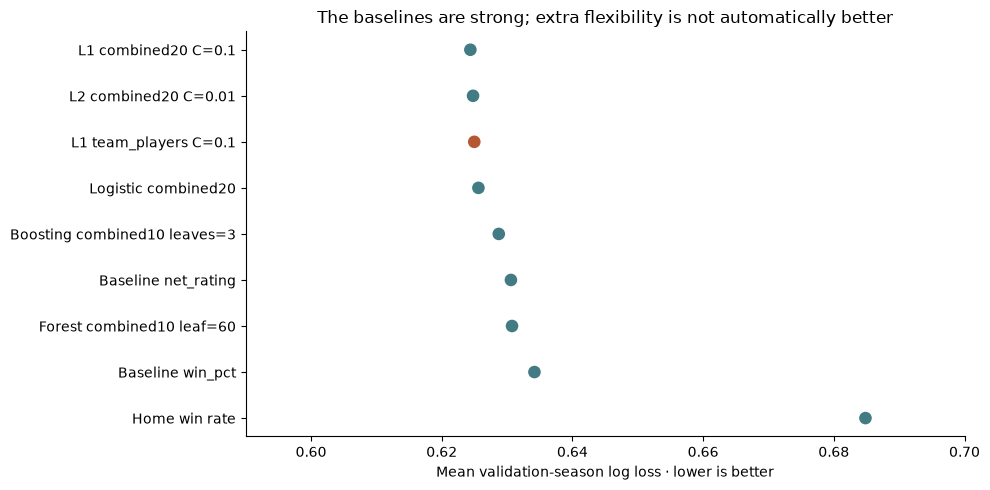

In [8]:
families = pd.read_csv(TABLES / "model_family_comparison.csv")
display(
    families[
        [
            "family",
            "name",
            "features",
            "n_features",
            "log_loss",
            "brier",
            "auc",
            "accuracy",
            "selected",
        ]
    ].round(4)
)
display(
    common[["family", "log_loss", "brier", "auc", "accuracy", "train_log_loss"]].round(
        4
    )
)
fig, ax = plt.subplots(figsize=(10, 5))
ordered = families.sort_values("log_loss", ascending=False)
colors = [CLAY if x else TEAL for x in ordered.selected]
ax.scatter(ordered.log_loss, ordered.name, c=colors, s=65)
ax.set(
    xlabel="Mean validation-season log loss · lower is better",
    xlim=(0.59, 0.70),
    title="The baselines are strong; extra flexibility is not automatically better",
)
finish(fig, "story_model_comparison.png")

The best L1 candidate reaches 0.62438 mean loss; the best forest reaches 0.63075 and shallow boosting 0.62873. The net-rating baseline is 0.63058. The matched-input table supports the same broad conclusion: tree flexibility does not earn an advantage in this search. These are comparisons among the settings tried, not a claim that all possible forests or boosting models must lose.

## 7. Where is the training–validation gap?

I look at both sides of the fit. A flexible model may memorize idiosyncrasies in the development games; a heavily penalized model may underfit. The difference is diagnostic evidence, not a literal decomposition of prediction error into bias and variance.

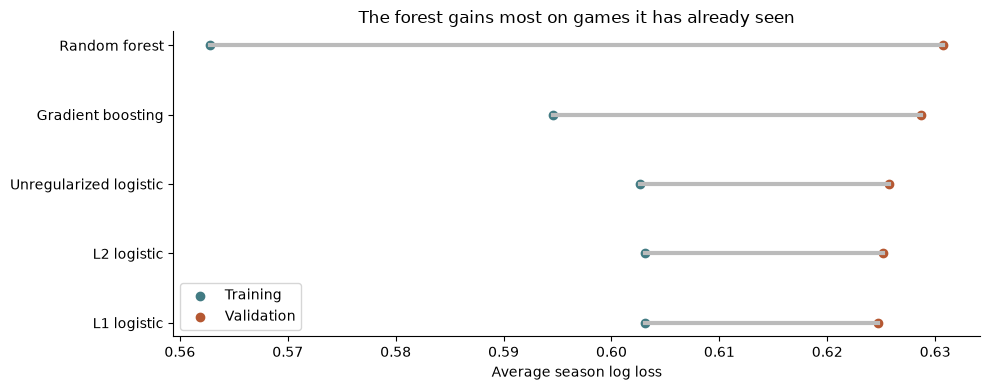

,family,train_log_loss,log_loss,generalization_gap
0,L1 logistic,0.6031,0.6247,0.0216
1,L2 logistic,0.6031,0.6251,0.0220
2,Unregularized logistic,0.6027,0.6258,0.0231
3,Gradient boosting,0.5945,0.6287,0.0342
4,Random forest,0.5628,0.6308,0.0680


In [9]:
gap = common.sort_values("log_loss")
fig, ax = plt.subplots(figsize=(10, 4))
for i, row in enumerate(gap.itertuples()):
    ax.plot([row.train_log_loss, row.log_loss], [i, i], color="#bbb", linewidth=3)
ax.scatter(gap.train_log_loss, range(len(gap)), color=TEAL, label="Training")
ax.scatter(gap.log_loss, range(len(gap)), color=CLAY, label="Validation")
ax.set_yticks(range(len(gap)), gap.family)
ax.set(
    xlabel="Average season log loss",
    title="The forest gains most on games it has already seen",
)
ax.legend()
finish(fig, "story_generalization_gap.png")
display(gap[["family", "train_log_loss", "log_loss", "generalization_gap"]].round(4))

The best combined forest's gap is about 0.068, versus roughly 0.022 for the comparable regularized linear models. Its lower training loss does not carry forward. Boosting with more leaves also fits training data more closely without improving validation. This is why I did not use complexity itself as a project objective.

## 8. Do the rankings hold across seasons?

A mean can hide reversals. I inspect each later season to see whether one model wins because of one unusually favorable year. These are the same validation seasons used to choose settings, so their variation is descriptive rather than a confidence interval for independent experiments.

name,Baseline net_rating,Baseline win_pct,Boosting combined10 leaves=3,Forest combined10 leaf=60,L1 team_players C=0.1
season,,,,,
2017,0.6145,0.6166,0.6086,0.6078,0.6065
2018,0.6215,0.6240,0.6160,0.6193,0.6143
2019,0.6246,0.6236,0.6294,0.6329,0.6209
2020,0.6327,0.6410,0.6262,0.6291,0.6244
2021,0.6419,0.6473,0.6424,0.6441,0.6371
2022,0.6483,0.6526,0.6497,0.6513,0.6466


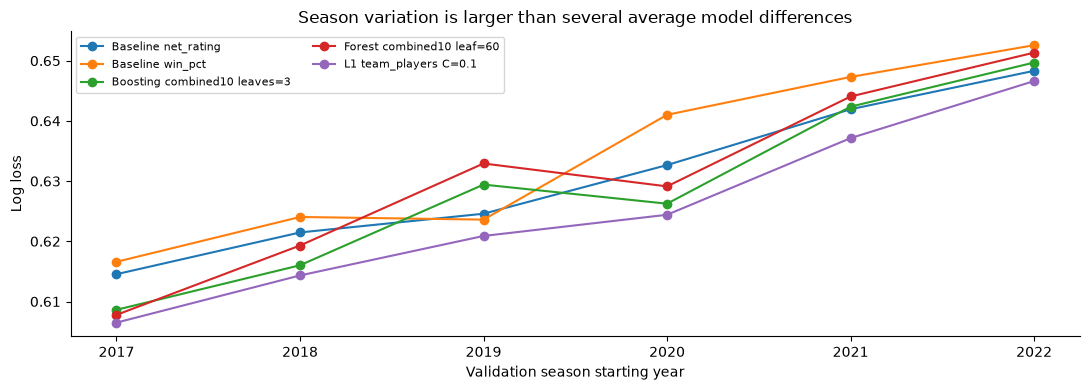

In [10]:
names = [
    selection["config"]["name"],
    "Baseline net_rating",
    "Baseline win_pct",
    "Forest combined10 leaf=60",
    "Boosting combined10 leaves=3",
]
annual = folds[folds.name.isin(names)].pivot(
    index="season", columns="name", values="log_loss"
)
display(annual.round(4))
fig, ax = plt.subplots(figsize=(11, 4))
annual.plot(ax=ax, marker="o")
ax.set(
    xlabel="Validation season starting year",
    ylabel="Log loss",
    title="Season variation is larger than several average model differences",
)
ax.legend(fontsize=8, ncol=2)
finish(fig, "story_season_comparison.png")

Several model differences are only a few thousandths, while performance moves more across seasons. I avoid calling a tiny average edge decisive. The final untouched-season evaluation was therefore essential, and the next notebook retains its original predictions instead of retuning after seeing them.

## 9. Which basketball inputs earned their place?

To make the feature choice clearer, I hold L1 regularization at C=.1 and compare the team set with recent-window and player additions. This controls the model family and penalty, though correlated inputs can still redistribute coefficients. The one-variable baselines are separate reference points.

,features,n_features,log_loss,brier,accuracy
52,team,11,0.62813,0.21910,0.64411
44,recent5,13,0.62757,0.21887,0.64432
25,recent10,13,0.62696,0.21855,0.64863
24,recent20,13,0.62672,0.21841,0.64711
4,team_players,22,0.62498,0.21763,0.65174
3,combined5,24,0.62492,0.21762,0.65205
1,combined10,24,0.62472,0.21751,0.65112
0,combined20,24,0.62438,0.21732,0.65187


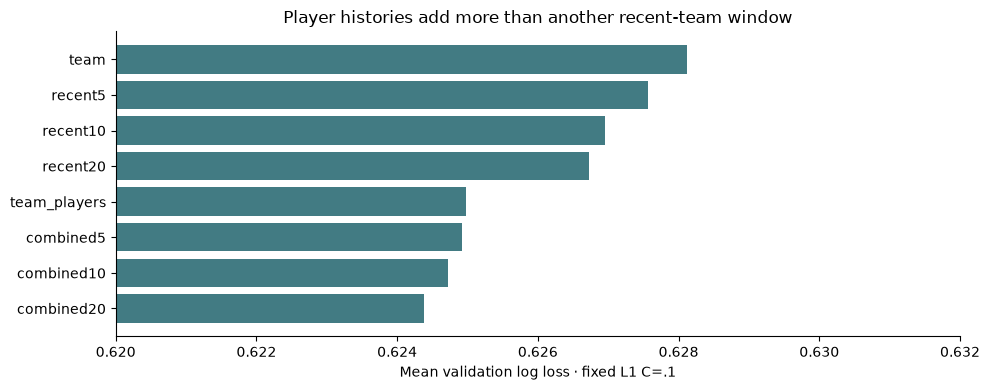

,season,Baseline net_rating,L1 team C=0.1,L1 team_players C=0.1,players_minus_team
0,2017,0.61454,0.61134,0.60649,-0.00485
1,2018,0.62147,0.61796,0.61433,-0.00363
2,2019,0.62458,0.62113,0.62089,-0.00024
3,2020,0.63266,0.63019,0.62441,-0.00578
4,2021,0.64194,0.64241,0.63714,-0.00527
5,2022,0.64832,0.64572,0.64662,0.00090


In [11]:
feature_names = [
    "team",
    "recent5",
    "recent10",
    "recent20",
    "team_players",
    "combined5",
    "combined10",
    "combined20",
]
fixed = summary[summary.name.isin([f"L1 {s} C=0.1" for s in feature_names])].copy()
fixed["order"] = fixed.features.map({s: i for i, s in enumerate(feature_names)})
fixed = fixed.sort_values("order")
display(fixed[["features", "n_features", "log_loss", "brier", "accuracy"]].round(5))
fig, ax = plt.subplots(figsize=(10, 4))
ax.barh(fixed.features.iloc[::-1], fixed.log_loss.iloc[::-1], color=TEAL)
ax.set(
    xlabel="Mean validation log loss · fixed L1 C=.1",
    xlim=(0.62, 0.632),
    title="Player histories add more than another recent-team window",
)
finish(fig, "story_feature_choices.png")
display(pd.read_csv(TABLES / "player_comparison_by_season.csv").round(5))

Player histories improve the team model in five of six validation seasons, lowering average loss from 0.62813 to 0.62498. The gain is not universal: the last validation season is slightly worse. Recent-team windows help too, but their additional gain after player histories is small. This distinction is more informative than saying “more features improved the model.”

## 10. Compare L1 and L2 instead of assuming one should win

L1 can remove inputs; L2 can share weight across related inputs. I test both on the same team-plus-player set. Smaller C means stronger shrinkage. The unregularized comparison uses a very large C rather than a different preprocessing path.

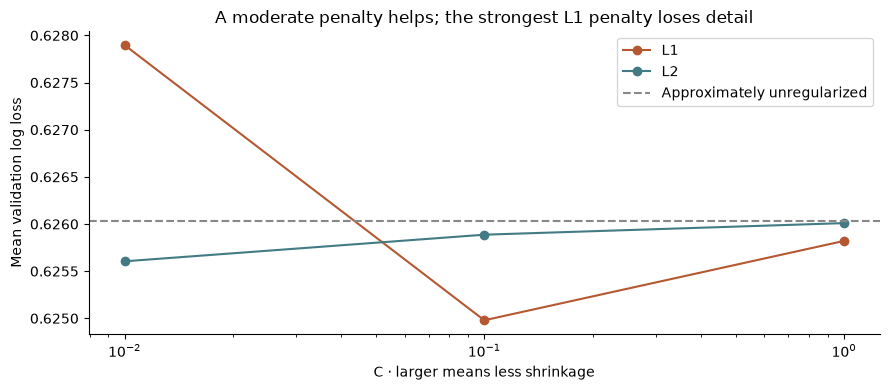

,name,C,log_loss,train_log_loss
0,L1 team_players C=0.1,0.10,0.62498,0.60364
1,L2 team_players C=0.01,0.01,0.62560,0.60368
2,L1 team_players C=1,1.00,0.62582,0.60316
3,L2 team_players C=0.1,0.10,0.62589,0.60318
4,L2 team_players C=1,1.00,0.62601,0.60315
5,L1 team_players C=0.01,0.01,0.62790,0.60896


In [12]:
reg = summary[
    summary.features.eq("team_players") & summary.name.str.startswith(("L1", "L2"))
].merge(pd.DataFrame(configs)[["name", "C"]], on="name")
fig, ax = plt.subplots()
for prefix, color in [("L1", CLAY), ("L2", TEAL)]:
    group = reg[reg.name.str.startswith(prefix)].sort_values("C")
    ax.plot(group.C, group.log_loss, "o-", color=color, label=prefix)
ordinary = summary.loc[summary.name.eq("Logistic team_players"), "log_loss"].iloc[0]
ax.axhline(ordinary, color="#888", linestyle="--", label="Approximately unregularized")
ax.set(
    xscale="log",
    xlabel="C · larger means less shrinkage",
    ylabel="Mean validation log loss",
    title="A moderate penalty helps; the strongest L1 penalty loses detail",
)
ax.legend()
finish(fig, "story_regularization.png")
display(
    reg[["name", "C", "log_loss", "train_log_loss"]].sort_values("log_loss").round(5)
)

L1 C=.1 is best for this set at 0.62498. L2 C=.01 is close at 0.62561; ordinary logistic is 0.62603. Stronger L1 shrinkage at C=.01 raises loss to 0.62790. That suggests a balance rather than an argument that sparsity is always better. These differences are small enough to report without overstating them.

## 11. Are the coefficients stable enough to interpret?

Because net rating and record overlap strongly, I inspect coefficient directions across expanding fits. An input that changes sign or regularly shrinks to zero is a weaker basis for a basketball explanation. L1 is not a cure for multicollinearity or a causal identification strategy.

,mean,min,max,std
feature,,,,
net_rating_diff,0.4512,0.4240,0.5045,0.0281
win_pct_diff,0.2813,0.2289,0.3191,0.0358
back_to_back_diff,-0.0914,-0.1199,-0.0586,0.0235
scoring_concentration_diff,0.0819,0.0561,0.1094,0.0181
weighted_absence_diff,-0.0720,-0.0940,-0.0572,0.0152
weighted_ppa_diff,0.0687,0.0411,0.0903,0.0177
games_last7_diff,-0.0640,-0.0750,-0.0553,0.0085
efg_diff,0.0592,0.0174,0.0887,0.0277


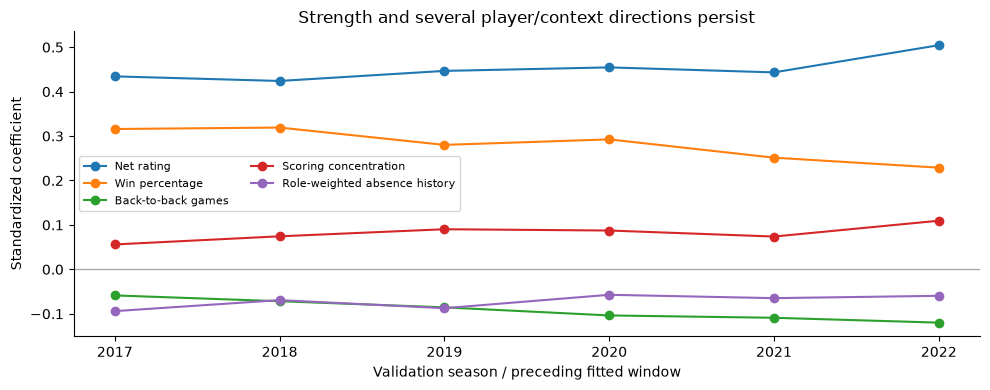

In [13]:
coefs = pd.read_csv(TABLES / "cv_coefficients.csv.gz")
selected_coefs = coefs[coefs.name.eq(selection["config"]["name"])]
stable = selected_coefs.groupby("feature").coefficient.agg(
    ["mean", "min", "max", "std"]
)
top = stable["mean"].abs().nlargest(8).index
display(stable.loc[top].round(4))
fig, ax = plt.subplots(figsize=(10, 4))
for feature in top[:5]:
    values = selected_coefs[selected_coefs.feature.eq(feature)].sort_values("season")
    ax.plot(values.season, values.coefficient, "o-", label=feature_label(feature))
ax.axhline(0, color="#aaa", linewidth=1)
ax.set(
    xlabel="Validation season / preceding fitted window",
    ylabel="Standardized coefficient",
    title="Strength and several player/context directions persist",
)
ax.legend(fontsize=8, ncol=2)
finish(fig, "story_coefficient_stability.png")

Net rating is consistently the largest signal. Record, back-to-backs, historical absence, scoring concentration and role-weighted scoring have stable directions across the development fits. Small, unstable coefficients are not headline findings. The final zero coefficients are inspected after fitting all development games in notebook 4.

## 12. Apply the selection rule, then freeze

The rule was specified before the original test: rank mean validation log loss; among candidates within .001 of the best, prefer fewer candidate inputs, then a linear model, then lower loss. Counting candidate inputs is conservative—it does not use a full-data L1 sparsity count to pick a winner.

In [14]:
minimum = summary.log_loss.min()
close = summary[summary.log_loss.le(minimum + 0.001)].sort_values(
    ["n_features", "log_loss"]
)
display(close[["name", "n_features", "log_loss", "brier"]].round(6))
chosen = select_candidate(summary)
assert chosen == selection["config"]["name"]
print("Chosen:", chosen)
print(
    "Distance from the lowest validation loss:",
    float(summary.set_index("name").loc[chosen, "log_loss"] - minimum),
)
print("Final fit seasons:", selection["train_seasons"])
print("Final test season:", selection["test_season"])

,name,n_features,log_loss,brier
4,L1 team_players C=0.1,22,0.624979,0.217632
0,L1 combined20 C=0.1,24,0.624380,0.217322
1,L1 combined10 C=0.1,24,0.624724,0.217509
2,L2 combined20 C=0.01,24,0.624788,0.217503
3,L1 combined5 C=0.1,24,0.624924,0.217623
5,L2 combined10 C=0.01,24,0.625119,0.217690
6,L1 combined20 C=1,24,0.625349,0.217765
7,L2 combined20 C=0.1,24,0.625377,0.217779


Chosen: L1 team_players C=0.1
Distance from the lowest validation loss: 0.0005993593000001018
Final fit seasons: [2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022]
Final test season: 2023


The lowest mean loss is L1 with combined twenty-game form and player inputs. The smaller team-plus-player version is only 0.000599 worse and uses 22 rather than 24 inputs, so the fixed rule selects it. The six-input compact model is outside the tolerance. This is a reasoned tradeoff, not a claim that the chosen model won every metric or every year.

The original selection was committed before evaluating 2023–24. This reporting revision leaves that model, its coefficients, its probabilities and the .5 favorite threshold unchanged. No new model is chosen because its test score happens to look better.

The remaining question is whether the extra work holds up on the reserved games, including against the easy-to-explain record rule. [Next: probabilities, picks, calibration and mistakes](04_model_interpretation.ipynb).